In [2]:
from google.colab import drive
drive.mount('/content/drive')
# monta o Google Drive, onde ficam os dados processados e os modelos

Mounted at /content/drive


In [3]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, UpSampling2D, concatenate, Conv2DTranspose, BatchNormalization, Dropout, Lambda, ReLU
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Activation, MaxPool2D, Concatenate
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, TensorBoard, ReduceLROnPlateau, CSVLogger
import numpy as np
from tensorflow.keras.metrics import MeanIoU
import keras
from keras import ops

In [ ]:
# hiper parametros
height_img = 288
width_img = 288
canais = 3
epochs = 50
batch_size = 16
lr = 0.0001

In [5]:
# carregando os dados de treino e validação
x_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_train.npy')
y_train = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_train.npy')
x_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/x_val.npy')
y_val = np.load('/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/processed/train/y_val.npy')

### Para facilitar a conexão entre as camadas convolucionais, encoder e decoders, separei em funções onde no final serão chamadas para a composiçãoo do modelo final

In [6]:
def convolucao(input, filters):
  x = Conv2D(filters,3, padding='same')(input)
  # Convolução de filters features maps que captura as principais informações da imagem
  x = BatchNormalization()(x)
  # normalização dos dados
  x = Activation('relu')(x)
  # função de ativação que subistui valores negativos por 0

#repetição da convolução
  x = Conv2D(filters,3, padding='same')(x)
  x = BatchNormalization()(x)
  x = Activation('relu')(x)

  return x

In [7]:
# o encoder vai realizar usar a convolução e diminuir gradativamente a dimensionalidade da imagem, pegando somente as caracteristicas essencias da imagem
def encoder(input,filters):
  x = convolucao(input,filters)
  # convolução
  p = MaxPool2D((2,2))(x)
  # vai diminuir a dimensionalidade pela metade
  return x, p

In [8]:
def decoder(input, skip_features, filters):
  # como o bloco encoder diminui a dimensionalidade pegando suas principais caracteristicas
  # o decoder vai fazer o contrário, vai aumentar a dimensionalidade com as caracteristicas aprendidas no encoder

  # Na arquitetura U-Net, para cada bloco decoder é pego como se fosse uma referencia de como era a imagem no bloco encoder
  # resumindo: para o decoder nao se perder ao classificar os pixels ele usa esse concatenate como referencia

  x = Conv2DTranspose(filters, (2,2), strides=2, padding='same')(input)

  x = Concatenate()([x, skip_features])
    # como dito antes, ira pegar como referencia o bloco encoder
  x = convolucao(x,filters)
  # convolucao
  return x

In [9]:
def modelo_unet(input_shape):
# chamando todas as funções e motando a arquitetura
  inputs = Input(input_shape)

    # o encoder como ele diminui a dimensionalidade e aumaneta o numero de feature maps
    # em s1 temos a convolução e em p o poll, retornos da função encoder
    # inputs vai ser o tamanho da imagem e canais
    # e na chamada do encoder terá a quantidade de filtros que cada camada utilizará na convolução
  s1,p1 = encoder(inputs, 64)
  s2,p2 = encoder(p1,128)
  s3,p3 = encoder(p2,256)
  s4,p4 = encoder(p3,512)

  b1 = convolucao(p4, 1024)
  # b1 é a convolução base da rede, após isso o decoder vai atuar

  # o decoder vai aumentar a dimensionalidade, entao vai diminuir o numero de feature maps e aumentar a dimensionalidade da imagem
  d1 = decoder(b1, s4,512)
  d2 = decoder(d1, s3, 256)
  d3 = decoder(d2, s2, 128)
  d4 = decoder(d3, s1, 64)

  outputs = Conv2D(5,1, padding='same', activation='softmax')(d4)
  # a funcao de ativação softmax retorna uma probabilidade para cada classe

  model = Model(inputs, outputs, name='U-Net_segmentation_rice')
  # cria o modelo
  return model

In [10]:
dice = keras.losses.Dice(axis=(0, 1, 2))
# loss dice oficial do keras, com axis=(0, 1, 2) calcula o dice separado para cada uma das 5 classes e depois faz a media
# assim o fundo pesa 1/5 e nao domina como acontece na acuracia
# o dice precisa da mascara em one-hot, no mesmo formato da saida do softmax
ce = keras.losses.SparseCategoricalCrossentropy()

def ce_dice_loss(y_true, y_pred):
    y_true_oh = ops.one_hot(ops.cast(ops.squeeze(y_true, axis=-1), 'int32'), 5)
    # transforma a mascara de inteiros (0 a 4) em one-hot
    return ce(y_true, y_pred) + dice(y_true_oh, y_pred)
    # cross entropy da estabilidade no inicio do treino, dice trata o desbalanceamento entre fundo e lesao


In [11]:
model = modelo_unet((height_img, width_img, canais))
# criando o modelo

In [12]:
model.compile(optimizer=Adam(learning_rate=lr), loss=ce_dice_loss, metrics=[MeanIoU(num_classes=5, sparse_y_true=True, sparse_y_pred=False, name='mean_io_u')])
# compilando o modelo com o otimizador Adam, a loss cross entropy + dice e o MeanIoU como medida para avaliar o modelo durante o treino
# a acuracia estava muito alta pois o modelo pode prever totalmente o fundo, que é a classe majoritaria em todas as imagens
# o MeanIoU calcula o IoU de cada classe separadamente e faz a media, assim o fundo pesa igual
# sparse_y_true=True pois as mascaras estao como inteiros, sparse_y_pred=False pois a saida do modelo sao probabilidades (softmax)
# o name='mean_io_u' garante que o checkpoint encontre a metrica val_mean_io_u mesmo se a celula for rodada mais de uma vez
# a loss soma a cross entropy esparsa (estabilidade) com o dice por classe (trata o desbalanceamento entre fundo e lesao)


In [13]:
model.summary()

Model: "U-Net_segmentation_rice"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 288, 288,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 288, 288,  │      1,792 │ input_layer[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 288, 288,  │        256 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 288, 288,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 288, 288,  │     36,928 │ activation[0][0]  │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 288, 288,  │        256 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 288, 288,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 144, 144,  │          0 │ activation_1[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 144, 144,  │     73,856 │ max_pooling2d[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 144, 144,  │        512 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 144, 144,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 144, 144,  │    147,584 │ activation_2[0][… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 144, 144,  │        512 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 144, 144,  │          0 │ batch_normalizat… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 72, 72,    │          0 │ activation_3[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 72, 72,    │    295,168 │ max_pooling2d_1[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 72, 72,    │      1,024 │ conv2d_4[0][0]  

 Total params: 31,055,557 (118.47 MB)

 Trainable params: 31,043,781 (118.42 MB)

 Non-trainable params: 11,776 (46.00 KB)

In [14]:
path_model = '/content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet_dice.keras'

In [17]:
checkpointer = ModelCheckpoint(path_model, verbose=1, save_best_only=True, monitor='val_mean_io_u', mode='max')
# salva o melhor modelo alcançado durante o treino, medido pelo IoU
# quanto mais proximo de 1 melhor
early_stopper = EarlyStopping(patience = 8, monitor='val_loss')
# para o treino caso após 8 epocas o val_loss nao tenha melhorado
lr_reducer = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=3, min_lr=0.000001, verbose=1)
# reduz o learning rate se apos 3 epocas o val_loss nao apresentar melhoras
checks = [checkpointer, lr_reducer, early_stopper]


In [18]:
treino = model.fit(x_train, y_train,validation_data=(x_val, y_val),epochs=epochs,batch_size=batch_size,callbacks=checks)
# treinando o modelo

Epoch 1/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 790ms/step - loss: 1.6803 - mean_io_u: 0.2072
Epoch 1: val_mean_io_u improved from None to 0.24728, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet_dice.keras

Epoch 1: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet_dice.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 306s 983ms/step - loss: 1.3408 - mean_io_u: 0.2360 - val_loss: 1.3118 - val_mean_io_u: 0.2473 - learning_rate: 1.0000e-04
Epoch 2/50
297/297 ━━━━━━━━━━━━━━━━━━━━ 0s 536ms/step - loss: 1.0412 - mean_io_u: 0.2802
Epoch 2: val_mean_io_u improved from 0.24728 to 0.37915, saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet_dice.keras

Epoch 2: finished saving model to /content/drive/MyDrive/LAMIA - Bootcamp/card29/segmentation_rice/models/U-Net/modelo_unet_dice.keras
297/297 ━━━━━━━━━━━━━━━━━━━━ 172s 578ms/step - loss: 0

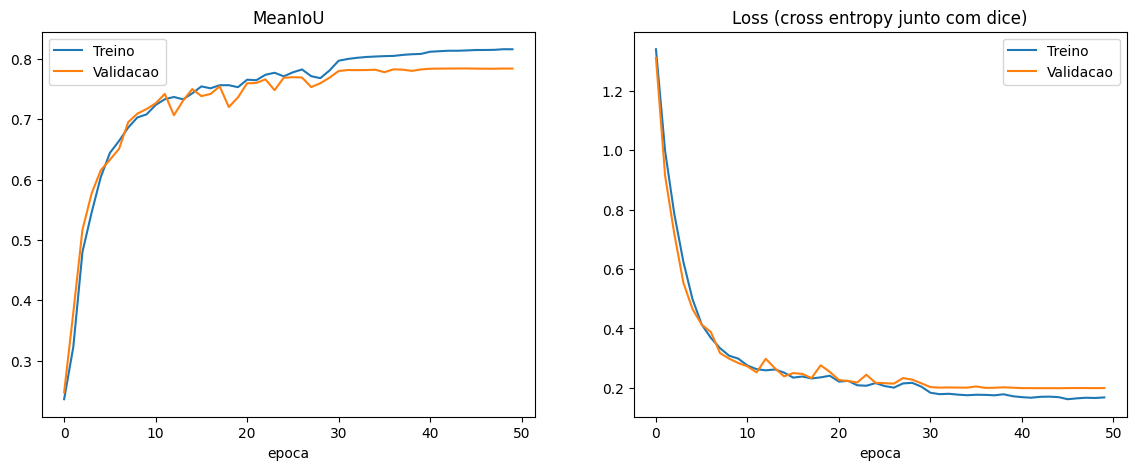

In [19]:
import matplotlib.pyplot as plt
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(treino.history['mean_io_u'], label='Treino')
plt.plot(treino.history['val_mean_io_u'], label='Validacao')
plt.title('MeanIoU')
plt.xlabel('epoca')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(treino.history['loss'], label='Treino')
plt.plot(treino.history['val_loss'], label='Validacao')
plt.title('Loss (cross entropy junto com dice)')
plt.xlabel('epoca')
plt.legend()

plt.show()
